In [ ]:
!pip install keras-tuner --quiet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 5.9 MB/s eta 0:00:00


## Supervised Classification

### 1. Load data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
DATASET_DIR = "/content/drive/Shareddrives/CV_Project/Supervised_Classification/data/IndustryBiscuit/DS_multiclass"

Mounted at /content/drive


In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import os

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.19.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
IMG_SIZE = (256, 256)
BATCH_SIZE = 32

train_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "train"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

valid_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "valid"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

test_ds_raw = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(DATASET_DIR, "test"),
    label_mode="categorical",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)


Found 3918 files belonging to 4 classes.
Found 490 files belonging to 4 classes.
Found 492 files belonging to 4 classes.


In [ ]:
class_names = train_ds_raw.class_names
class_names

['Defect_Color', 'Defect_No', 'Defect_Object', 'Defect_Shape']

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds_raw.prefetch(AUTOTUNE)
valid_ds = valid_ds_raw.prefetch(AUTOTUNE)
test_ds = test_ds_raw.prefetch(AUTOTUNE)

### 2. CNN Model

#### 2.1 Basic CNN

In [ ]:
import keras_tuner as kt
from tensorflow.keras import layers, models, regularizers
import tensorflow as tf

IMG_SIZE = (256, 256)
NUM_CLASSES = 4

def build_cnn_model(hp):
    model = models.Sequential()
    model.add(layers.Rescaling(1./255, input_shape=(256,256,3)))

    # Conv layers
    model.add(layers.Conv2D(32,3,padding="same",activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(64,3,padding="same",activation="relu"))
    model.add(layers.MaxPooling2D())
    model.add(layers.Conv2D(128,3,padding="same",activation="relu"))
    model.add(layers.MaxPooling2D())

    model.add(layers.Flatten())

    # Dense layer units as hyperparameter
    hp_units = hp.Choice("dense_units", [64,128,256])
    model.add(layers.Dense(hp_units, activation="relu"))

    # Dropout rate hyperparameter
    hp_dropout = hp.Choice("dropout", [0.2, 0.3, 0.4, 0.5])
    model.add(layers.Dropout(hp_dropout))

    # Output
    model.add(layers.Dense(NUM_CLASSES, activation="softmax"))

    # LR hyperparameter
    hp_lr = hp.Choice("learning_rate", [1e-2,1e-3,3e-4,1e-4])

    # Optimizer hyperparameter
    hp_opt = hp.Choice("optimizer", ["adam","rmsprop","sgd"])

    if hp_opt == "adam":
        opt = tf.keras.optimizers.Adam(hp_lr)
    elif hp_opt == "rmsprop":
        opt = tf.keras.optimizers.RMSprop(hp_lr)
    else:
        opt = tf.keras.optimizers.SGD(hp_lr, momentum=0.9)

    model.compile(
        optimizer=opt,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


In [ ]:
tuner = kt.Hyperband(
    build_cnn_model,
    objective='val_accuracy',
    max_epochs=15,
    factor=3,
    directory='tuner_dir',
    project_name='basic_cnn'
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

tuner.search(
    train_ds_raw,
    validation_data=valid_ds_raw,
    epochs=15,
    callbacks=[stop_early]
)

Trial 30 Complete [00h 04m 12s]
val_accuracy: 0.9489796161651611

Best val_accuracy So Far: 0.9693877696990967
Total elapsed time: 00h 58m 25s


In [ ]:
best_hps = tuner.get_best_hyperparameters(1)[0]
#print(best_hps)

basic_cnn_model = build_cnn_model(best_hps)

history = basic_cnn_model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=30,
    callbacks=[stop_early]
)

Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


123/123 ━━━━━━━━━━━━━━━━━━━━ 20s 136ms/step - accuracy: 0.4851 - loss: 1.1781 - val_accuracy: 0.8388 - val_loss: 0.5386
Epoch 2/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.8490 - loss: 0.4843 - val_accuracy: 0.8959 - val_loss: 0.3482
Epoch 3/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 14s 117ms/step - accuracy: 0.9066 - loss: 0.2927 - val_accuracy: 0.9469 - val_loss: 0.2170
Epoch 4/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 119ms/step - accuracy: 0.9546 - loss: 0.1631 - val_accuracy: 0.9510 - val_loss: 0.2008
Epoch 5/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 119ms/step - accuracy: 0.9680 - loss: 0.1156 - val_accuracy: 0.9469 - val_loss: 0.1985
Epoch 6/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 119ms/step - accuracy: 0.9820 - loss: 0.0706 - val_accuracy: 0.9653 - val_loss: 0.1698
Epoch 7/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 117ms/step - accuracy: 0.9842 - loss: 0.0607 - val_accuracy: 0.9327 - val_loss: 0.2982
Epoch 8/30
123/123 ━━━━━━━━━━━━━━━━━━━━ 15s 118ms/step - accuracy: 0.9837 - loss: 0.0497 - val

In [ ]:
tuner_basic = kt.Hyperband(
    build_cnn_model,
    objective='val_accuracy',
    max_epochs=15,
    factor=3,
    directory='tuner_dir',
    project_name='basic_cnn'
)

best_hps_basic = tuner_basic.get_best_hyperparameters(1)[0]
best_hps_basic.values

Reloading Tuner from tuner_dir/basic_cnn/tuner0.json


{'dense_units': 128,
 'dropout': 0.4,
 'learning_rate': 0.0003,
 'optimizer': 'adam',
 'tuner/epochs': 15,
 'tuner/initial_epoch': 5,
 'tuner/bracket': 1,
 'tuner/round': 1,
 'tuner/trial_id': '0019'}

In [ ]:
import matplotlib.pyplot as plt

def plot_training_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc)+1)

    plt.figure(figsize=(12,5))

    # Accuracy
    plt.subplot(1,2,1)
    plt.plot(epochs, acc, 'b-', label="Training Acc")
    plt.plot(epochs, val_acc, 'r-', label="Validation Acc")
    plt.title("Accuracy Over Epochs")
    plt.legend()

    # Loss
    plt.subplot(1,2,2)
    plt.plot(epochs, loss, 'b-', label="Training Loss")
    plt.plot(epochs, val_loss, 'r-', label="Validation Loss")
    plt.title("Loss Over Epochs")
    plt.legend()

    plt.show()


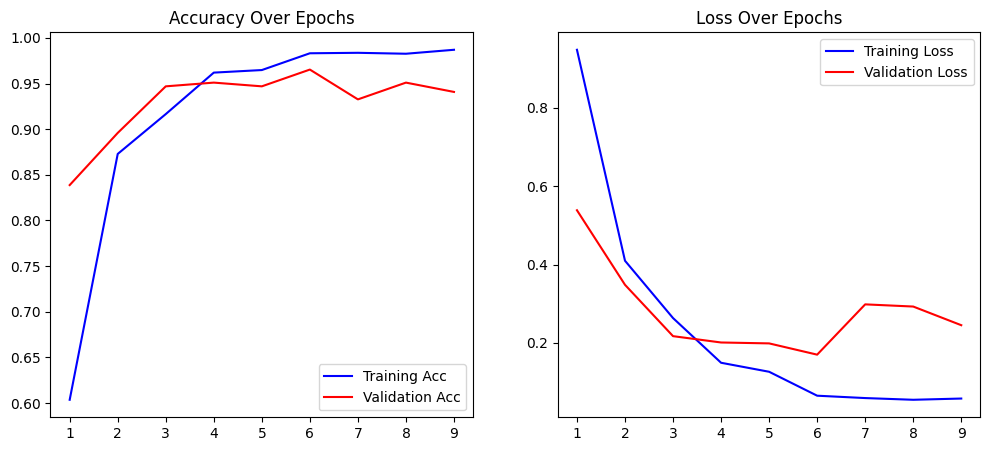

In [ ]:
plot_training_history(history)


In [ ]:
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_curve, auc, precision_recall_curve
)
import matplotlib.pyplot as plt

def evaluate_model(model, test_ds, class_names):
    # -----------------------------
    # 1. Collect all predictions
    # -----------------------------
    y_true = []
    y_pred = []

    for img, label in test_ds:
        preds = model.predict(img)
        y_true.extend(np.argmax(label.numpy(), axis=1))
        y_pred.extend(np.argmax(preds, axis=1))

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    # -----------------------------
    # 2. Confusion Matrix
    # -----------------------------
    cm = confusion_matrix(y_true, y_pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d",
                xticklabels=class_names,
                yticklabels=class_names,
                cmap="Blues")
    plt.title("Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.show()

    # -----------------------------
    # 3. Classification Report
    # -----------------------------
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # -----------------------------
    # 4. Misclassified Samples
    # -----------------------------
    print("Showing some misclassified samples...")

    incorrect_idx = np.where(y_true != y_pred)[0]
    if len(incorrect_idx) == 0:
        print("No misclassified samples!")
        return

    plt.figure(figsize=(12,7))
    for i, idx in enumerate(incorrect_idx[:6]):
        img, label = list(test_ds.unbatch().take(idx+1))[idx]
        plt.subplot(2,3,i+1)
        plt.imshow(img.numpy().astype("uint8"))
        plt.title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}")
        plt.axis("off")

    plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


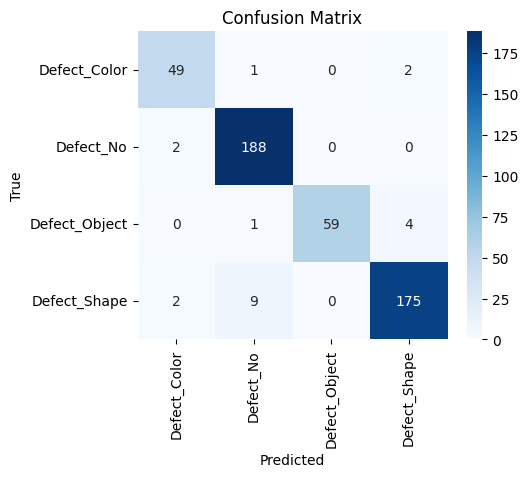


Classification Report:
               precision    recall  f1-score   support

 Defect_Color       0.92      0.94      0.93        52
    Defect_No       0.94      0.99      0.97       190
Defect_Object       1.00      0.92      0.96        64
 Defect_Shape       0.97      0.94      0.95       186

     accuracy                           0.96       492
    macro avg       0.96      0.95      0.95       492
 weighted avg       0.96      0.96      0.96       492

Showing some misclassified samples...


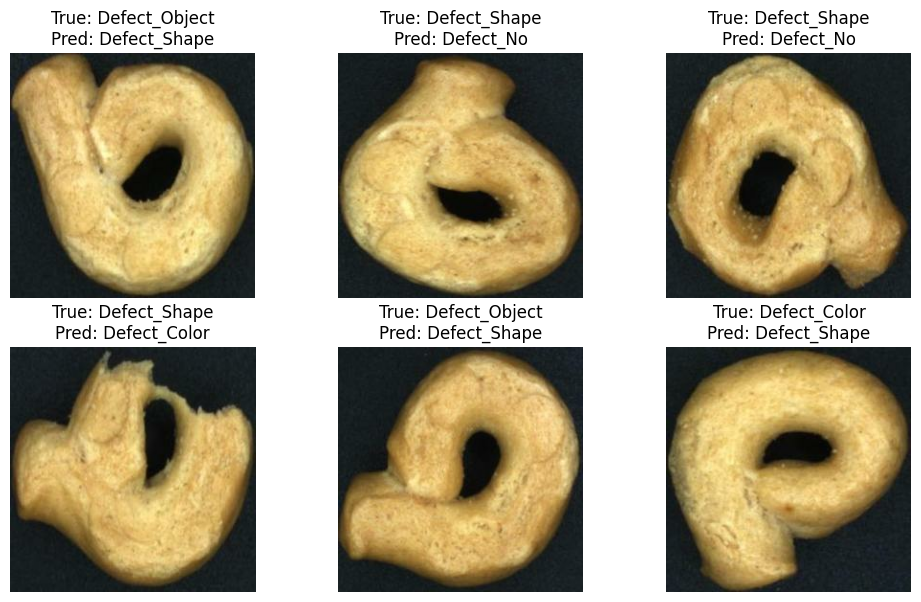

In [ ]:
evaluate_model(basic_cnn_model, test_ds, class_names)


Actually here the misclassified samples' images and labels are not consistent. Apologize for the mistake. Please just ingnore that.

In [ ]:
!zip -r tuner_backup.zip tuner_dir/

from google.colab import files
files.download("tuner_backup.zip")

  adding: tuner_dir/ (stored 0%)
  adding: tuner_dir/basic_cnn/ (stored 0%)
  adding: tuner_dir/basic_cnn/trial_0022/ (stored 0%)
  adding: tuner_dir/basic_cnn/trial_0022/trial.json (deflated 65%)
  adding: tuner_dir/basic_cnn/trial_0022/checkpoint.weights.h5 (deflated 13%)
  adding: tuner_dir/basic_cnn/trial_0022/build_config.json (deflated 11%)
  adding: tuner_dir/basic_cnn/trial_0028/ (stored 0%)
  adding: tuner_dir/basic_cnn/trial_0028/trial.json (deflated 65%)
  adding: tuner_dir/basic_cnn/trial_0028/checkpoint.weights.h5 (deflated 26%)
  adding: tuner_dir/basic_cnn/trial_0028/build_config.json (deflated 11%)
  adding: tuner_dir/basic_cnn/trial_0015/ (stored 0%)
  adding: tuner_dir/basic_cnn/trial_0015/trial.json (deflated 65%)
  adding: tuner_dir/basic_cnn/trial_0015/checkpoint.weights.h5 (deflated 13%)
  adding: tuner_dir/basic_cnn/trial_0015/build_config.json (deflated 11%)
  adding: tuner_dir/basic_cnn/oracle.json (deflated 69%)
  adding: tuner_dir/basic_cnn/trial_0017/ (store

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!cp -r tuner_dir/ /content/drive/MyDrive/tuner_backup/
